# Mini Project 5

## Agaba Steven. 
### Registration Number: S26M19/002. 
### Access Number: B38624

# Taxi Route Revenue, Pricing and Fleet Planner

In [1]:
import math
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import solve

from src.route import Route
from src.forecasting import (
    MovingAverage,
    ExponentialSmoothing,
    LinearTrend
)

In [2]:
ntinda = [
    35,40,42,50,55,
    60,48,52,47,45
]

entebbe = [
    60,58,65,70,72,
    80,75,68,66,64
]

mukono = [
    45,47,50,49,55,
    62,58,53,51,50
]

In [3]:
routes = [
    Route(
        "Ntinda",
        ntinda,
        2000
    ),

    Route(
        "Entebbe",
        entebbe,
        5000
    ),

    Route(
        "Mukono",
        mukono,
        3000
    )
]

In [4]:
summary = []

for route in routes:

    summary.append({
        "Route":
        route.name,

        "Total Revenue":
        route.total_revenue(),

        "Mean":
        route.mean(),

        "Variance":
        route.variance(),

        "Std Dev":
        route.std_dev()
    })

pd.DataFrame(
    summary
)

,Route,Total Revenue,Mean,Variance,Std Dev
0,Ntinda,948000,47.4,54.266667,7.366591
1,Entebbe,3390000,67.8,45.066667,6.713171
2,Mukono,1560000,52.0,26.444444,5.142416


Qd = 120 - 0.02P

Qs = 10 + 0.03P

Q + 0.02P = 120
Q - 0.03P = 10


In [5]:
A = np.array([
    [1, 0.02],
    [1,-0.03]
])

B = np.array([
    120,
    10
])

Q, P = solve(
    A,
    B
)

print(
    "Equilibrium Passengers:",
    round(Q,2)
)

print(
    "Equilibrium Fare:",
    round(P,2)
)

Equilibrium Passengers: 76.0
Equilibrium Fare: 2200.0


In [6]:
if 2000 > P:

    print(
        "Current fare is ABOVE equilibrium."
    )

else:

    print(
        "Current fare is BELOW equilibrium."
    )

Current fare is BELOW equilibrium.


In [7]:
def mae(
    actual,
    predicted
):

    return np.mean(
        np.abs(
            actual - predicted
        )
    )

In [8]:
best_models = {}

for route in routes:

    data = route.passengers

    records = []

    for name, model in {

        "Moving Average":
        MovingAverage(),

        "Linear Trend":
        LinearTrend()

    }.items():

        predictions = []
        actuals = []

        for i in range(
            3,
            len(data)
        ):

            forecast = (
                model.forecast(
                    data[:i]
                )
            )

            predictions.append(
                forecast
            )

            actuals.append(
                data[i]
            )

        score = mae(
            np.array(actuals),
            np.array(predictions)
        )

        records.append([
            name,
            score
        ])

    best = min(
        records,
        key=lambda x:x[1]
    )

    best_models[
        route.name
    ] = best[0]

    print(
        route.name,
        records
    )

Ntinda [['Moving Average', np.float64(7.523809523809525)], ['Linear Trend', np.float64(7.873469387755104)]]
Entebbe [['Moving Average', np.float64(7.190476190476192)], ['Linear Trend', np.float64(7.7113378684807135)]]
Mukono [['Moving Average', np.float64(5.333333333333333)], ['Linear Trend', np.float64(6.390589569161003)]]


In [9]:
alphas = np.arange(
    0.1,
    1.0,
    0.1
)

best_alpha = None
best_score = float(
    "inf"
)

data = ntinda

for alpha in alphas:

    model = (
        ExponentialSmoothing(
            alpha
        )
    )

    predictions = []
    actuals = []

    for i in range(
        3,
        len(data)
    ):

        predictions.append(
            model.forecast(
                data[:i]
            )
        )

        actuals.append(
            data[i]
        )

    score = mae(
        np.array(actuals),
        np.array(predictions)
    )

    if score < best_score:

        best_score = score
        best_alpha = alpha

best_alpha

np.float64(0.9)

In [10]:
day11_forecasts = {}

for route in routes:

    model = LinearTrend()

    prediction = (
        model.forecast(
            route.passengers
        )
    )

    day11_forecasts[
        route.name
    ] = prediction

day11_forecasts

{'Ntinda': np.float64(53.66666666666664),
 'Entebbe': np.float64(72.1333333333333),
 'Mukono': np.float64(56.06666666666665)}

In [11]:
for route in routes:

    passengers = (
        day11_forecasts[
            route.name
        ]
    )

    revenue = (
        passengers
        * route.fare
    )

    print(
        route.name,
        round(revenue,2)
    )

Ntinda 107333.33
Entebbe 360666.67
Mukono 168200.0


In [12]:
fleet_results = []

for route in routes:

    passengers = (
        day11_forecasts[
            route.name
        ]
    )

    capacity = (
        14 * 8
    )

    vehicles = math.ceil(
        passengers
        /
        capacity
    )

    vehicles = math.ceil(
        vehicles * 1.15
    )

    fleet_results.append({
        "Route":
        route.name,

        "Vehicles":
        vehicles
    })

pd.DataFrame(
    fleet_results
)

,Route,Vehicles
0,Ntinda,2
1,Entebbe,2
2,Mukono,2


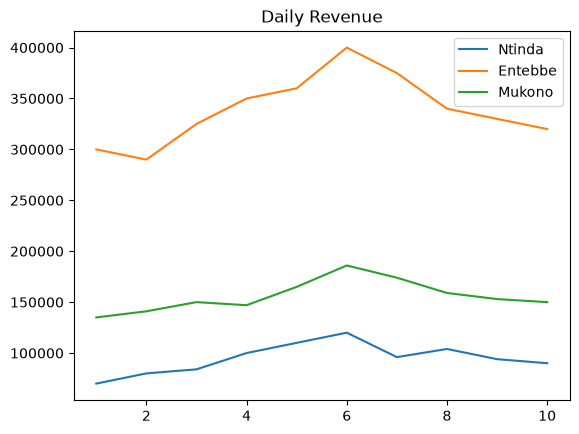

In [13]:
for route in routes:

    actual = (
        route.daily_revenue()
    )

    plt.plot(
        range(
            1,
            len(actual)+1
        ),
        actual,
        label=route.name
    )

plt.legend()

plt.title(
    "Daily Revenue"
)

plt.show()

In [14]:
rng = np.random.default_rng(
    42
)

days = np.arange(
    60
)

seasonal = []

for d in days:

    weekday = d % 7

    base = 50

    if weekday == 5:
        base = 70

    elif weekday == 6:
        base = 35

    seasonal.append(
        base
        + rng.normal(
            0,
            5
        )
    )

seasonal = np.array(
    seasonal
)

In [15]:
predictions = []
actuals = []

for i in range(
    7,
    len(seasonal)
):

    predictions.append(
        seasonal[i-7]
    )

    actuals.append(
        seasonal[i]
    )

seasonal_mae = mae(
    np.array(actuals),
    np.array(predictions)
)

print(
    "Seasonal Naive MAE:",
    seasonal_mae
)

Seasonal Naive MAE: 4.844583438707094


# Findings and Limitations

The route analysis indicated substantial differences in passenger demand and revenue generation across the three routes. The equilibrium analysis showed the market-clearing fare that balances passenger demand with transport supply. Comparison with the current Ntinda fare provided insight into whether the route may be underpriced or overpriced relative to the theoretical equilibrium.

Forecasting results demonstrated that predictive performance varies by route and forecasting method. Backtesting enabled objective model comparison using out-of-sample errors. The best-performing model was then used to estimate day-11 demand and revenue.

Fleet-planning calculations translated demand forecasts into operational decisions by estimating the number of vehicles required while including a 15 percent contingency buffer. The extension analysis showed that when strong weekly patterns exist, seasonal-naive forecasting can outperform simple moving averages because it captures recurring weekly behavior.

A limitation of the project is the short demand history of only ten observed days. Passenger demand may also be influenced by weather, fuel prices, holidays, competition, and economic conditions that are not captured in this simplified model.
